In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as fn
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
import matplotlib.pyplot as plt

In [2]:
spark = SparkSession.builder.master('local').getOrCreate()

In [4]:
from google.colab import drive
drive.mount ('/content/drive')

Mounted at /content/drive


In [6]:
path = '/content/drive/MyDrive/Colab Notebooks/cancer_tumor.csv'

In [7]:
df1 = spark.read.csv(path, inferSchema=True, header=True)
df1.show(6)

+---------+-----------+------------+--------------+---------+---------------+----------------+--------------+-------------------+-------------+----------------------+---------+----------+------------+-------+-------------+--------------+------------+-----------------+-----------+--------------------+------------+-------------+---------------+----------+----------------+-----------------+---------------+--------------------+--------------+-----------------------+
|diagnosis|radius_mean|texture_mean|perimeter_mean|area_mean|smoothness_mean|compactness_mean|concavity_mean|concave points_mean|symmetry_mean|fractal_dimension_mean|radius_se|texture_se|perimeter_se|area_se|smoothness_se|compactness_se|concavity_se|concave points_se|symmetry_se|fractal_dimension_se|radius_worst|texture_worst|perimeter_worst|area_worst|smoothness_worst|compactness_worst|concavity_worst|concave points_worst|symmetry_worst|fractal_dimension_worst|
+---------+-----------+------------+--------------+---------+-----

In [8]:
df2 = df1.withColumn("diagnosis", fn.when(fn.col("diagnosis") == 'M', 1).otherwise(0))
df2.show()

+---------+-----------+------------+--------------+---------+---------------+----------------+--------------+-------------------+-------------+----------------------+---------+----------+------------+-------+-------------+--------------+------------+-----------------+-----------+--------------------+------------+-------------+---------------+----------+----------------+-----------------+---------------+--------------------+--------------+-----------------------+
|diagnosis|radius_mean|texture_mean|perimeter_mean|area_mean|smoothness_mean|compactness_mean|concavity_mean|concave points_mean|symmetry_mean|fractal_dimension_mean|radius_se|texture_se|perimeter_se|area_se|smoothness_se|compactness_se|concavity_se|concave points_se|symmetry_se|fractal_dimension_se|radius_worst|texture_worst|perimeter_worst|area_worst|smoothness_worst|compactness_worst|concavity_worst|concave points_worst|symmetry_worst|fractal_dimension_worst|
+---------+-----------+------------+--------------+---------+-----

In [9]:
Pred_corr = [
    'radius_mean', 'texture_mean', 'area_mean', 'perimeter_mean',
    'compactness_mean', 'radius_se', 'area_se', 'perimeter_se',
    'radius_worst', 'texture_worst', 'area_worst', 'concavity_worst',
    'symmetry_worst'
]

vector_col = "Predictors"
assembler = VectorAssembler(inputCols=Pred_corr, outputCol=vector_col)
output = assembler.transform(df2)
vector= output.select("Predictors", "diagnosis")
vector.show(5)

+--------------------+---------+
|          Predictors|diagnosis|
+--------------------+---------+
|[17.99,10.38,1001...|        1|
|[20.57,17.77,1326...|        1|
|[19.69,21.25,1203...|        1|
|[11.42,20.38,386....|        1|
|[20.29,14.34,1297...|        1|
+--------------------+---------+
only showing top 5 rows


In [10]:
train_data, test_data = vector.randomSplit([0.8, 0.2])

In [11]:
regressor = LogisticRegression(featuresCol="Predictors", labelCol="diagnosis", maxIter=1000)
lr_model = regressor.fit(train_data)

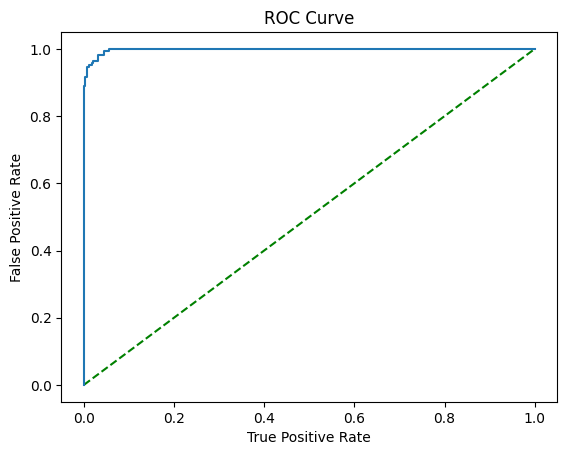

TrainSet areaUnderROC: 0.9979587542087542


In [12]:
lr_model_summary = lr_model.summary
roc = lr_model_summary.roc.toPandas()

plt.plot([0, 1], [0, 1], 'g--')
plt.plot(roc['FPR'], roc['TPR'])
plt.ylabel('False Positive Rate')
plt.xlabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

print('TrainSet areaUnderROC: ' + str(lr_model_summary.areaUnderROC))

In [13]:
lr_model_test = lr_model.transform(test_data)
evaluator = BinaryClassificationEvaluator(rawPredictionCol='rawPrediction', labelCol='diagnosis')
print('Test Area Under ROC: ',(evaluator.evaluate(lr_model_test)))

Test Area Under ROC:  0.9799568300955906
